# Local CPU Dueling Double DQN for Flappy Bird (v2)

This notebook trains an improved, more reliable local checkpoint on Windows /
Python 3.11. It keeps the algorithm that already worked reasonably well
(Dueling Double DQN + Prioritized Experience Replay) and fixes the two things
that made the previous checkpoint unreliable:

1. A **fixed, short (400,000-transition) epsilon decay** that collapsed
   exploration long before a multi-million-transition policy had stabilized.
2. **Hard target-network resyncs** every 10,000 transitions, which
   destabilized the learned value function. The previous checkpoint's own
   evaluation history (`old_artifects/flappy_ddqn_score_1000_metadata.json`)
   shows the mean 5-seed score falling from 861 at step 2,750,001 to 396 by
   step 3,000,000 — the exported "best" model was a lucky snapshot, not a
   converged policy.

Both are fixed here with **soft (Polyak) target updates** and an
**epsilon decay that scales with the configured training budget**, without
adding a new algorithm or new dependencies.

Default training budget: **more than 3,000,000 environment transitions**
(`TOTAL_TRANSITIONS` in the configuration cell). Set `FLAPPY_RUN_MODE=smoke`
in the environment to run a ~25,000-transition end-to-end validation instead
of full training; `FLAPPY_RUN_MODE=benchmark` measures throughput for the
currently configured worker settings without training.

Re-running this notebook (`Run All`) is safe: it auto-resumes from
`artifacts/<experiment>/checkpoints/latest.pt` if one already exists, instead
of requiring a manually pasted checkpoint path.


## 1. Python 3.11 setup and local paths

Open this notebook with the **Flappy Bird Python 3.11** kernel. The setup
cell fails immediately under any other Python major/minor version, forces
CPU execution (this tiny MLP gains nothing from a GPU: PCIe/launch overhead
would dominate a ~90k-parameter network), and limits native thread pools
before importing NumPy or PyTorch.


In [1]:
import os
import sys

if sys.version_info[:2] != (3, 11):
    raise RuntimeError(
        "This notebook requires Python 3.11.x. "
        f"Current interpreter: {sys.version.split()[0]} at {sys.executable}"
    )

# Environment overrides let smoke-testing and resume validation exercise this
# notebook without editing any cell; leaving them unset gives the intended
# full-budget defaults described in the configuration section below.
RUN_MODE = os.environ.get("FLAPPY_RUN_MODE", "full").strip().lower()
if RUN_MODE not in {"full", "smoke", "benchmark"}:
    raise ValueError("FLAPPY_RUN_MODE must be full, smoke, or benchmark.")

TORCH_THREADS = int(os.environ.get("FLAPPY_TORCH_THREADS", "2"))
for variable in (
    "OMP_NUM_THREADS",
    "MKL_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
):
    os.environ[variable] = str(TORCH_THREADS)

import copy
import io
import json
import math
import platform
import random
import shutil
import time
from datetime import datetime
from pathlib import Path

import gymnasium as gym
import imageio.v2 as imageio
import matplotlib.pyplot as plt
import numpy as np
import psutil
import pygame
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image as PILImage
from PIL import ImageDraw
from tqdm.auto import tqdm

import flappy_bird_gymnasium  # registers FlappyBird-v0
from flappy_local_runtime import (
    close_environments,
    create_training_vec_env,
    resolve_repository_root,
)
from flappy_model import (
    DuelingQNetwork,
    EXPECTED_ALGORITHM,
    atomic_torch_save,
    build_model_config,
    load_model_from_checkpoint,
    load_torch_payload,
    soft_update,
    validate_checkpoint_metadata,
)

PROJECT_ROOT = resolve_repository_root()
ARTIFACTS_ROOT = PROJECT_ROOT / "artifacts"
ARTIFACTS_ROOT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cpu")

torch.set_num_threads(TORCH_THREADS)
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass

PHYSICAL_CORES = psutil.cpu_count(logical=False) or 1
LOGICAL_THREADS = psutil.cpu_count(logical=True) or os.cpu_count() or 1
CPU_MODEL = platform.processor() or "Unknown"

print(f"Python: {sys.version.split()[0]}")
print(f"sys.executable: {sys.executable}")
print(f"PyTorch: {torch.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Gymnasium: {gym.__version__}")
print(f"Pygame: {pygame.version.ver}")
print(f"CPU model: {CPU_MODEL}")
print(f"Physical CPU cores: {PHYSICAL_CORES}")
print(f"Logical CPU threads: {LOGICAL_THREADS}")
print(f"Run mode: {RUN_MODE}")
print(f"Training device: {DEVICE}")
print(f"PyTorch threads: {TORCH_THREADS}")


<python311>\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.11.9
sys.executable: <python311>\python.exe
PyTorch: 2.12.1+cpu
NumPy: 2.4.1
Gymnasium: 1.3.0
Pygame: 2.6.1
CPU model: Intel64 Family 6 Model 186 Stepping 2, GenuineIntel
Physical CPU cores: 14
Logical CPU threads: 20
Run mode: full
Training device: cpu
PyTorch threads: 2


## 2. Algorithm and training configuration

- **Dueling DQN** learns a state-value stream and a per-action advantage
  stream, then combines them into Q-values.
- **Double DQN** selects the next action with the online network and
  evaluates that action with the target network, reducing overestimation.
- **Prioritized Experience Replay (PER)** samples transitions in proportion
  to TD-error-derived priorities and corrects the bias with importance
  weights.
- **Soft (Polyak) target updates** blend the target network towards the
  online network by a small fraction (`TARGET_TAU`) every gradient step,
  replacing the old hard resync every 10,000 transitions that caused the
  instability described above.
- **Biased epsilon-greedy exploration** does not choose flap/no-flap 50/50: a
  flap is an impulse that should be rare, so exploratory decisions flap with
  probability 0.08. The decay now scales with the configured training
  budget instead of a fixed 400,000-transition schedule.
- **Reward shaping** is training-only (see below); evaluation always uses
  the unmodified environment, true `info["score"]`, and greedy
  (`epsilon=0.0`) actions.

All of the following is single-source configuration: every training-affecting
constant lives in the next cell. `TOTAL_TRANSITIONS` defaults to
**5,000,000**, comfortably above the required 3,000,000-transition minimum.


In [2]:
# ---------------------------------------------------------------------------
# Identity, reproducibility, and experiment layout
# ---------------------------------------------------------------------------
SEED = 42
PIPE_GAP = 100
TRAINING_SCORE_LIMIT = 1_000_000  # effectively unlimited during training rollouts

EXPERIMENT_NAME = os.environ.get("FLAPPY_EXPERIMENT_NAME", "ddqn_local_v2")
FORCE_FRESH_START = os.environ.get("FLAPPY_FORCE_FRESH_START", "0").strip() == "1"

# Total environment transitions (frames collected across all workers) before
# stopping. This is distinct from: gradient updates (optimizer steps, see
# GRADIENT_STEPS below), episodes (full games played, tracked separately),
# and rendered frames (only relevant to the inference viewers, never counted
# here). Default clears the 3,000,000 requirement with margin; raising it
# and re-running this notebook continues training from the latest checkpoint
# automatically.
TOTAL_TRANSITIONS = int(os.environ.get("FLAPPY_TOTAL_TRANSITIONS", "5000000"))
assert TOTAL_TRANSITIONS > 0

SMOKE_TOTAL_TRANSITIONS = 25_000
RUN_TRANSITIONS = {
    "full": TOTAL_TRANSITIONS,
    "smoke": SMOKE_TOTAL_TRANSITIONS,
    "benchmark": 0,
}[RUN_MODE]

# ---------------------------------------------------------------------------
# Worker / optimizer ratio. 8 workers, 2 PyTorch threads, one gradient step
# per vector step (~1 update per 8 collected transitions) was selected by
# this repository's CPU benchmark on a 14-core/20-thread host. Re-run
# FLAPPY_RUN_MODE=benchmark and adjust these three values if your hardware
# differs significantly; the training loop reads them from here either way.
# ---------------------------------------------------------------------------
N_ENVS = int(os.environ.get("FLAPPY_N_ENVS", "8"))
GRADIENT_STEPS = int(os.environ.get("FLAPPY_GRADIENT_STEPS", "1"))
APPROX_TRANSITIONS_PER_UPDATE = N_ENVS / GRADIENT_STEPS

EVAL_INTERVAL = 250_000
CHECKPOINT_INTERVAL = 250_000
LOG_INTERVAL = max(2_000, min(50_000, (RUN_TRANSITIONS // 10) or 50_000))

BUFFER_SIZE = 500_000
LEARNING_STARTS = 20_000
BATCH_SIZE = 256
GAMMA = 0.99
LEARNING_RATE = 1e-4
HIDDEN_DIM = 192

# Soft target updates: see the reliability discussion in the section 2
# markdown cell above. tau=5e-3 is a standard literature default; it costs
# one extra elementwise parameter blend per gradient step (negligible on a
# ~90k-parameter network) and removes the discrete resync jump entirely.
TARGET_TAU = 5e-3

EPSILON_START = 1.0
EPSILON_END = 0.01
# Decay over the first 15% of the configured budget (floor 400,000
# transitions so short/smoke runs still get a sane schedule). A fixed
# 400,000-step decay was fine for a ~2,250,000-transition run but far too
# short for a 5,000,000+ run: exploration would vanish at the 8% mark and
# the greedy policy could lock in prematurely.
EPSILON_DECAY_STEPS = max(400_000, int(0.15 * TOTAL_TRANSITIONS))
EXPLORATION_FLAP_PROBABILITY = 0.08

PER_ALPHA = 0.3
PER_BETA_START = 0.4
PER_BETA_END = 1.0
PER_BETA_STEPS = TOTAL_TRANSITIONS

# ---------------------------------------------------------------------------
# Reward shaping (training only; evaluation always uses the unmodified
# environment and true info["score"]). Every term is documented here:
#
#   survival_reward (+0.05/frame) - keeps "stay alive" from ever looking
#       worse than acting randomly, without outweighing pipe-passing.
#   pipe_reward     (+5.0/pipe)   - the real objective: 100x survival_reward
#       so passing pipes dominates the return.
#   death_penalty   (-5.0)        - symmetric with pipe_reward, so avoiding
#       one death is worth roughly one pipe.
#   top_penalty     (-1.0)        - discourages hugging the ceiling; mirrors
#       the environment's own near-top danger signal (raw reward -0.5).
#   flap_cost       (-0.01/flap)  - new in v2: a tiny continuous cost on the
#       flap action, two orders of magnitude below pipe_reward/death_penalty,
#       so it only discourages *wasted*/spammed flapping and never
#       outweighs a flap that is actually needed to survive.
#
# Deliberately NOT included: any continuous reward for vertical position or
# gap-centering. That shaping has a well-known failure mode here: the agent
# learns to hover at the reward-maximizing altitude instead of reacting to
# the actual pipe gap - reward hacking that looks like progress on the
# shaped return while true pipe score stays flat.
# ---------------------------------------------------------------------------
SURVIVAL_REWARD = 0.05
PIPE_REWARD = 5.0
DEATH_PENALTY = -5.0
TOP_PENALTY = -1.0
FLAP_COST = -0.01
REWARD_SHAPING = {
    "survival_reward": SURVIVAL_REWARD,
    "pipe_reward": PIPE_REWARD,
    "death_penalty": DEATH_PENALTY,
    "top_penalty": TOP_PENALTY,
    "flap_cost": FLAP_COST,
}

FINAL_HOLDOUT_SEEDS = [1_000_001, 1_000_002, 1_000_003, 1_000_004, 1_000_005]
SMOKE_EVALUATION_SEEDS = [800_001, 800_002, 800_003, 800_004, 800_005]
GIF_SEED = 900_001

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

RUN_TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
if RUN_MODE == "full":
    # Stable, un-timestamped directory: re-running this notebook (e.g. after
    # an interruption) resolves to the same experiment and auto-resumes
    # instead of requiring a manually copy-pasted checkpoint path. Smoke and
    # benchmark modes keep timestamped, disposable directories so repeated
    # validation runs never collide with each other or with real training.
    RUN_DIR = ARTIFACTS_ROOT / EXPERIMENT_NAME
else:
    RUN_DIR = ARTIFACTS_ROOT / f"{EXPERIMENT_NAME}_{RUN_MODE}_{RUN_TIMESTAMP}"
CHECKPOINT_DIR = RUN_DIR / "checkpoints"
LATEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "latest.pt"
LOCK_PATH = RUN_DIR / "train.lock"

assert not RUN_DIR.exists() or RUN_DIR.is_relative_to(ARTIFACTS_ROOT)

print(f"Experiment: {EXPERIMENT_NAME}")
print(f"Run directory: {RUN_DIR}")
print(f"Run transition budget: {RUN_TRANSITIONS:,}")
print(f"N_ENVS={N_ENVS} | GRADIENT_STEPS={GRADIENT_STEPS} | update ratio=1:{APPROX_TRANSITIONS_PER_UPDATE:.2f}")
print(f"Epsilon: {EPSILON_START} -> {EPSILON_END} over {EPSILON_DECAY_STEPS:,} transitions")
print(f"Target network: soft update, tau={TARGET_TAU}")
print(f"Reward shaping: {json.dumps(REWARD_SHAPING)}")


Experiment: ddqn_local_v2
Run directory: <repo>\artifacts\ddqn_local_v2
Run transition budget: 5,000,000
N_ENVS=8 | GRADIENT_STEPS=1 | update ratio=1:8.00
Epsilon: 1.0 -> 0.01 over 750,000 transitions
Target network: soft update, tau=0.005
Reward shaping: {"survival_reward": 0.05, "pipe_reward": 5.0, "death_penalty": -5.0, "top_penalty": -1.0, "flap_cost": -0.01}


## 3. Prioritized replay buffer

The sum tree stores proportional PER priorities in O(log N) update and
sampling time, with vectorized batch insertion/sampling/priority-propagation
so an 8-worker rollout never falls back to a per-transition Python loop.
Replay contents are intentionally not included in checkpoints: a
500,000-transition replay snapshot would make frequent checkpoints very
large, so a resumed run's replay buffer restarts empty and warms for another
`LEARNING_STARTS` transitions. The `DuelingQNetwork` architecture itself
lives in `flappy_model.py`, shared with both inference viewers, so the
network definition exists exactly once in the repository.


In [3]:
class PrioritizedReplayBuffer:
    def __init__(self, capacity, state_dim, alpha=0.3, priority_epsilon=1e-5):
        self.capacity = int(capacity)
        self.state_dim = int(state_dim)
        self.alpha = float(alpha)
        self.priority_epsilon = float(priority_epsilon)
        tree_capacity = 1
        while tree_capacity < self.capacity:
            tree_capacity *= 2
        self.tree_capacity = tree_capacity
        self.priority_tree = np.zeros(2 * tree_capacity, dtype=np.float32)
        self.states = np.empty((self.capacity, self.state_dim), dtype=np.float32)
        self.next_states = np.empty_like(self.states)
        self.actions = np.empty(self.capacity, dtype=np.int64)
        self.rewards = np.empty(self.capacity, dtype=np.float32)
        self.dones = np.empty(self.capacity, dtype=np.float32)
        self.position = 0
        self.size = 0
        self.max_priority = 1.0
        self._sample_cache = {}

    def __len__(self):
        return self.size

    def _set_priorities_batch(self, data_indices, priorities):
        data_indices = np.asarray(data_indices, dtype=np.int64)
        priorities = np.asarray(priorities, dtype=np.float32)
        order = np.argsort(data_indices)
        sorted_indices = data_indices[order]
        sorted_priorities = priorities[order]
        unique_indices, starts = np.unique(sorted_indices, return_index=True)
        unique_priorities = np.maximum.reduceat(sorted_priorities, starts)

        tree_indices = self.tree_capacity + unique_indices
        deltas = unique_priorities - self.priority_tree[tree_indices]
        self.priority_tree[tree_indices] = unique_priorities

        while tree_indices.size and tree_indices[0] > 1:
            parents = tree_indices // 2
            unique_parents, inverse = np.unique(parents, return_inverse=True)
            parent_deltas = np.zeros(len(unique_parents), dtype=np.float32)
            np.add.at(parent_deltas, inverse, deltas)
            self.priority_tree[unique_parents] += parent_deltas
            tree_indices = unique_parents
            deltas = parent_deltas

    def add(self, state, action, reward, next_state, done):
        self.add_batch(
            np.expand_dims(state, axis=0),
            np.asarray([action]),
            np.asarray([reward]),
            np.expand_dims(next_state, axis=0),
            np.asarray([done]),
        )

    def add_batch(self, states, actions, rewards, next_states, dones):
        actions = np.asarray(actions, dtype=np.int64)
        count = len(actions)
        if count == 0:
            return
        if count > self.capacity:
            states = states[-self.capacity:]
            actions = actions[-self.capacity:]
            rewards = rewards[-self.capacity:]
            next_states = next_states[-self.capacity:]
            dones = dones[-self.capacity:]
            count = self.capacity

        indices = (self.position + np.arange(count, dtype=np.int64)) % self.capacity
        self.states[indices] = np.ascontiguousarray(states, dtype=np.float32)
        self.actions[indices] = actions
        self.rewards[indices] = np.asarray(rewards, dtype=np.float32)
        self.next_states[indices] = np.ascontiguousarray(next_states, dtype=np.float32)
        self.dones[indices] = np.asarray(dones, dtype=np.float32)
        self._set_priorities_batch(indices, np.full(count, self.max_priority, dtype=np.float32))
        self.position = (self.position + count) % self.capacity
        self.size = min(self.size + count, self.capacity)

    def sample(self, batch_size, beta, device):
        if self.size < batch_size:
            raise ValueError("Replay buffer does not contain enough samples.")
        total_priority = float(self.priority_tree[1])
        if total_priority <= 0:
            raise RuntimeError("Replay priorities must be positive.")
        segment = total_priority / batch_size
        masses = (np.arange(batch_size, dtype=np.float64) + np.random.random(batch_size)) * segment
        tree_indices = np.ones(batch_size, dtype=np.int64)
        while tree_indices[0] < self.tree_capacity:
            left = 2 * tree_indices
            left_priorities = self.priority_tree[left]
            go_right = masses >= left_priorities
            masses = np.where(go_right, masses - left_priorities, masses)
            tree_indices = left + go_right.astype(np.int64)
        indices = np.minimum(tree_indices - self.tree_capacity, self.size - 1)
        priorities = self.priority_tree[tree_indices]
        probabilities = np.maximum(priorities / total_priority, 1e-12)
        weights = (self.size * probabilities) ** (-float(beta))
        weights /= weights.max() + 1e-8

        cache = self._sample_cache.get(batch_size)
        if cache is None:
            cache = {
                "states": np.empty((batch_size, self.state_dim), dtype=np.float32),
                "actions": np.empty(batch_size, dtype=np.int64),
                "rewards": np.empty(batch_size, dtype=np.float32),
                "next_states": np.empty((batch_size, self.state_dim), dtype=np.float32),
                "dones": np.empty(batch_size, dtype=np.float32),
                "weights": np.empty(batch_size, dtype=np.float32),
            }
            self._sample_cache[batch_size] = cache
        np.take(self.states, indices, axis=0, out=cache["states"])
        np.take(self.actions, indices, axis=0, out=cache["actions"])
        np.take(self.rewards, indices, axis=0, out=cache["rewards"])
        np.take(self.next_states, indices, axis=0, out=cache["next_states"])
        np.take(self.dones, indices, axis=0, out=cache["dones"])
        cache["weights"][:] = weights

        return {
            "states": torch.from_numpy(cache["states"]).to(device),
            "actions": torch.from_numpy(cache["actions"]).to(device),
            "rewards": torch.from_numpy(cache["rewards"]).to(device),
            "next_states": torch.from_numpy(cache["next_states"]).to(device),
            "dones": torch.from_numpy(cache["dones"]).to(device),
            "weights": torch.from_numpy(cache["weights"]).to(device),
            "indices": indices,
        }

    def update_priorities(self, indices, td_errors):
        priorities = (np.abs(np.asarray(td_errors, dtype=np.float32)) + self.priority_epsilon) ** self.alpha
        self._set_priorities_batch(indices, priorities)
        self.max_priority = max(self.max_priority, float(priorities.max()))


## 4. Double-DQN optimization and deterministic evaluation

Training targets use the online network for action selection and the target
network for action evaluation (Double DQN), with a Huber loss weighted by PER
importance-sampling weights. Every optimizer step ends with a soft target
update. Evaluation environments are never reward-wrapped and never rendered
during checkpoint selection.


In [4]:
def linear_schedule(step, start_value, end_value, duration):
    fraction = min(max(step / max(duration, 1), 0.0), 1.0)
    return start_value + fraction * (end_value - start_value)


def optimize_double_dqn(
    online_network,
    target_network,
    optimizer,
    replay_buffer,
    batch_size,
    gamma,
    beta,
    tau,
    device=DEVICE,
    collect_metrics=True,
):
    batch = replay_buffer.sample(batch_size, beta, device)
    q_values = online_network(batch["states"]).gather(1, batch["actions"].unsqueeze(1)).squeeze(1)
    with torch.no_grad():
        next_actions = online_network(batch["next_states"]).argmax(dim=1, keepdim=True)
        next_q_values = target_network(batch["next_states"]).gather(1, next_actions).squeeze(1)
        targets = batch["rewards"] + gamma * (1.0 - batch["dones"]) * next_q_values
    td_errors = targets - q_values
    per_sample_loss = F.smooth_l1_loss(q_values, targets, reduction="none")
    loss = (batch["weights"] * per_sample_loss).mean()
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(online_network.parameters(), max_norm=10.0)
    optimizer.step()
    soft_update(online_network, target_network, tau)
    replay_buffer.update_priorities(batch["indices"], td_errors.detach().cpu().numpy())
    if not collect_metrics:
        return None
    return {
        "loss": float(loss.item()),
        "mean_q": float(q_values.detach().mean().item()),
        "mean_abs_td_error": float(td_errors.detach().abs().mean().item()),
    }


def make_evaluation_env(score_limit, render_mode=None):
    return gym.make(
        "FlappyBird-v0",
        render_mode=render_mode,
        use_lidar=False,
        normalize_obs=True,
        pipe_gap=PIPE_GAP,
        score_limit=int(score_limit),
        audio_on=False,
    )


def scaled_frame_safety_limit(score_limit):
    return max(10_000, int(score_limit) * 50 + 5_000)


@torch.no_grad()
def evaluate_dqn(network, seeds, score_limit, max_steps=None):
    was_training = network.training
    network.eval()
    max_steps = scaled_frame_safety_limit(score_limit) if max_steps is None else int(max_steps)
    episodes = []
    try:
        for seed in seeds:
            env = make_evaluation_env(score_limit, render_mode=None)
            try:
                observation, info = env.reset(seed=int(seed))
                total_reward = 0.0
                score = int(info.get("score", 0))
                terminated = truncated = False
                for steps in range(1, max_steps + 1):
                    action = int(
                        network.choose_actions(np.expand_dims(observation, axis=0), epsilon=0.0)[0]
                    )
                    observation, reward, terminated, truncated, info = env.step(action)
                    total_reward += float(reward)
                    score = int(info.get("score", score))
                    if terminated or truncated:
                        break
                else:
                    steps = max_steps
                target_reached = score >= score_limit
                if target_reached:
                    reason = "target reached"
                elif terminated:
                    reason = "terminated"
                elif truncated:
                    reason = "environment truncated"
                else:
                    reason = "safety frame limit"
                episodes.append(
                    {
                        "seed": int(seed),
                        "score": int(score),
                        "reward": float(total_reward),
                        "frames": int(steps),
                        "terminated": bool(terminated),
                        "truncated": bool(truncated),
                        "target_reached": bool(target_reached),
                        "termination_reason": reason,
                    }
                )
            finally:
                env.close()
    finally:
        if was_training:
            network.train()

    scores = [episode["score"] for episode in episodes]
    return {
        "seeds": [int(seed) for seed in seeds],
        "score_limit": int(score_limit),
        "episodes": episodes,
        "scores": scores,
        "rewards": [episode["reward"] for episode in episodes],
        "episode_lengths": [episode["frames"] for episode in episodes],
        "terminations": [episode["terminated"] for episode in episodes],
        "truncations": [episode["truncated"] for episode in episodes],
        "target_reached_flags": [episode["target_reached"] for episode in episodes],
        "mean_score": float(np.mean(scores)),
        "median_score": float(np.median(scores)),
        "std_score": float(np.std(scores)),
        "minimum_score": int(np.min(scores)),
        "maximum_score": int(np.max(scores)),
        "reached_limit_count": int(sum(score >= score_limit for score in scores)),
    }


## 5. Dynamic five-slot periodic evaluation

Periodic validation starts with seeds `[1, 2, 3, 4, 5]` and a score limit of
1000. Every successful slot is retired and replaced by a different
never-before-used seed. The limit rises by exactly 1000 once per evaluation
if any slot succeeds.

The checkpoint ranking key is:

`(highest_completed_level, slots_reaching_evaluated_limit, minimum_score, mean_score, maximum_score)`

`highest_completed_level` changes only when a slot actually completes the
evaluated level, so merely drifting to a higher pending limit can never
replace a stronger checkpoint. The `minimum_score` term is deliberately
checked before `mean_score`: it is the consistency criterion that stops a
single lucky episode from ever winning "best checkpoint" over a policy that
is reliably good across all five active seeds.


In [5]:
def initial_evaluation_state():
    return {
        "active_eval_seeds": [1, 2, 3, 4, 5],
        "next_available_eval_seed": 6,
        "used_eval_seeds": [1, 2, 3, 4, 5],
        "retired_eval_seeds": [],
        "evaluation_score_limit": 1000,
        "highest_completed_level": 0,
    }


def validate_evaluation_state(state):
    active = [int(value) for value in state["active_eval_seeds"]]
    used = {int(value) for value in state["used_eval_seeds"]}
    retired = {int(value) for value in state["retired_eval_seeds"]}
    assert len(active) == 5 and len(set(active)) == 5
    assert set(active).issubset(used)
    assert retired.issubset(used)
    assert set(active).isdisjoint(retired)
    assert int(state["next_available_eval_seed"]) not in used
    assert int(state["evaluation_score_limit"]) >= 1000
    return True


def advance_evaluation_state(state, scores):
    state_before = copy.deepcopy(state)
    validate_evaluation_state(state_before)
    if len(scores) != 5:
        raise ValueError("Exactly five periodic evaluation scores are required.")

    active = list(state_before["active_eval_seeds"])
    used = set(state_before["used_eval_seeds"])
    retired = set(state_before["retired_eval_seeds"])
    limit = int(state_before["evaluation_score_limit"])
    successful_slots = [index for index, score in enumerate(scores) if int(score) >= limit]

    next_seed = int(state_before["next_available_eval_seed"])
    replacements = {}
    if successful_slots:
        for slot in successful_slots:
            retired.add(active[slot])
            while next_seed in used:
                next_seed += 1
            replacements[slot] = next_seed
            active[slot] = next_seed
            used.add(next_seed)
            next_seed += 1
        next_limit = limit + 1000
        highest_completed = max(int(state_before["highest_completed_level"]), limit)
    else:
        next_limit = limit
        highest_completed = int(state_before["highest_completed_level"])

    while next_seed in used:
        next_seed += 1

    state_after = {
        "active_eval_seeds": active,
        "next_available_eval_seed": next_seed,
        "used_eval_seeds": sorted(used),
        "retired_eval_seeds": sorted(retired),
        "evaluation_score_limit": next_limit,
        "highest_completed_level": highest_completed,
    }
    validate_evaluation_state(state_after)
    return {
        "state_before": state_before,
        "state_after": state_after,
        "successful_slots": successful_slots,
        "replacement_seeds_by_slot": replacements,
        "evaluated_score_limit": limit,
    }


def checkpoint_ranking_key(evaluation_record):
    scores = [int(score) for score in evaluation_record["scores"]]
    return (
        int(evaluation_record["state_after"]["highest_completed_level"]),
        int(len(evaluation_record["successful_slots"])),
        int(min(scores)),
        float(np.mean(scores)),
        int(max(scores)),
    )


def run_evaluation_state_tests():
    base = initial_evaluation_state()

    none = advance_evaluation_state(base, [999, 20, 30, 40, 50])
    assert none["state_after"] == base

    one = advance_evaluation_state(base, [1000, 45, 500, 644, 754])
    assert one["state_after"]["active_eval_seeds"] == [6, 2, 3, 4, 5]
    assert one["state_after"]["next_available_eval_seed"] == 7
    assert one["state_after"]["evaluation_score_limit"] == 2000

    multiple = advance_evaluation_state(one["state_after"], [2000, 350, 2000, 900, 2000])
    assert multiple["state_after"]["active_eval_seeds"] == [7, 2, 8, 4, 9]
    assert multiple["state_after"]["next_available_eval_seed"] == 10
    assert multiple["state_after"]["evaluation_score_limit"] == 3000

    all_five = advance_evaluation_state(initial_evaluation_state(), [1000] * 5)
    replacements = list(all_five["replacement_seeds_by_slot"].values())
    assert len(replacements) == len(set(replacements)) == 5
    assert all_five["state_after"]["evaluation_score_limit"] == 2000
    assert set(replacements).isdisjoint({1, 2, 3, 4, 5})

    resumed = json.loads(json.dumps(multiple["state_after"]))
    assert resumed == multiple["state_after"]
    validate_evaluation_state(resumed)
    return {
        "no_success": "passed",
        "one_success": "passed",
        "multiple_successes": "passed",
        "all_successes": "passed",
        "unique_replacements": "passed",
        "single_limit_increment": "passed",
        "no_seed_reuse": "passed",
        "resume_state": "passed",
    }


EVALUATION_STATE_TEST_RESULTS = run_evaluation_state_tests()
print(json.dumps(EVALUATION_STATE_TEST_RESULTS, indent=2))


{
  "no_success": "passed",
  "one_success": "passed",
  "multiple_successes": "passed",
  "all_successes": "passed",
  "unique_replacements": "passed",
  "single_limit_increment": "passed",
  "no_seed_reuse": "passed",
  "resume_state": "passed"
}


## 6. Checkpointing, resume, and the training lock file

Checkpoints are written atomically (temp file + `os.replace`) and include
both networks, the optimizer, the global transition count, the model config,
the dynamic evaluation state, the best-ranking state, and the next scheduled
evaluation/checkpoint steps. Three kinds of checkpoint exist inside
`checkpoints/`:

- `latest.pt` - overwritten every checkpoint interval and at run end; this is
  the one auto-resume loads.
- `ddqn_<step>.pt` - numbered snapshots, never overwritten, kept for
  rollback/inspection.
- `../best_model.pt` - overwritten only when the five-slot ranking key
  improves; this is the checkpoint the final holdout and both viewers use by
  default.

A `train.lock` file (containing the writer's PID) prevents two training
processes from accidentally targeting the same experiment directory at once.


In [6]:
def build_training_model_config(state_dim, action_dim):
    return build_model_config(
        state_dim=state_dim,
        action_dim=action_dim,
        hidden_dim=HIDDEN_DIM,
        pipe_gap=PIPE_GAP,
        extra={
            "learning_rate": LEARNING_RATE,
            "gamma": GAMMA,
            "buffer_size": BUFFER_SIZE,
            "batch_size": BATCH_SIZE,
            "learning_starts": LEARNING_STARTS,
            "target_update_mode": "soft",
            "target_tau": TARGET_TAU,
            "epsilon_start": EPSILON_START,
            "epsilon_end": EPSILON_END,
            "epsilon_decay_steps": EPSILON_DECAY_STEPS,
            "exploration_flap_probability": EXPLORATION_FLAP_PROBABILITY,
            "per_alpha": PER_ALPHA,
            "per_beta_start": PER_BETA_START,
            "per_beta_end": PER_BETA_END,
            "per_beta_steps": PER_BETA_STEPS,
            "n_envs": N_ENVS,
            "gradient_steps": GRADIENT_STEPS,
            "approx_transitions_per_update": APPROX_TRANSITIONS_PER_UPDATE,
            "total_transitions": TOTAL_TRANSITIONS,
            "eval_interval": EVAL_INTERVAL,
            "checkpoint_interval": CHECKPOINT_INTERVAL,
            "reward_shaping": REWARD_SHAPING,
            "checkpoint_ranking_key": [
                "highest_completed_level",
                "slots_reaching_evaluated_limit",
                "minimum_score",
                "mean_score",
                "maximum_score",
            ],
        },
    )


def save_training_checkpoint(
    path,
    online_network,
    target_network,
    optimizer,
    global_step,
    model_config,
    evaluation_state,
    best_ranking_key,
    best_checkpoint_step,
    latest_evaluation,
    next_evaluation_step,
    next_checkpoint_step,
    run_status,
):
    payload = {
        "algorithm": EXPECTED_ALGORITHM,
        "online_state_dict": online_network.state_dict(),
        "target_state_dict": target_network.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "global_step": int(global_step),
        "model_config": dict(model_config),
        "replay_configuration": {
            "capacity": BUFFER_SIZE,
            "alpha": PER_ALPHA,
            "beta_start": PER_BETA_START,
            "beta_end": PER_BETA_END,
            "serialized": False,
            "resume_warmup_required": True,
        },
        "evaluation_state": copy.deepcopy(evaluation_state),
        "best_ranking_key": list(best_ranking_key),
        "best_checkpoint_step": best_checkpoint_step,
        "latest_evaluation": latest_evaluation,
        "next_scheduled_steps": {
            "evaluation": int(next_evaluation_step),
            "checkpoint": int(next_checkpoint_step),
        },
        "run_status": str(run_status),
    }
    atomic_torch_save(payload, path)


def create_networks_and_optimizer(state_dim, action_dim):
    online = DuelingQNetwork(state_dim, action_dim, HIDDEN_DIM).to(DEVICE)
    target = DuelingQNetwork(state_dim, action_dim, HIDDEN_DIM).to(DEVICE)
    target.load_state_dict(online.state_dict())
    target.eval()
    optimizer = torch.optim.Adam(online.parameters(), lr=LEARNING_RATE)
    return online, target, optimizer


def write_json(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with temporary.open("w", encoding="utf-8") as file:
        json.dump(payload, file, indent=2)
    os.replace(temporary, path)


def acquire_training_lock(lock_path):
    lock_path = Path(lock_path)
    if lock_path.exists():
        try:
            existing = json.loads(lock_path.read_text(encoding="utf-8"))
            existing_pid = int(existing.get("pid", -1))
        except (json.JSONDecodeError, ValueError, OSError):
            existing_pid = -1
        if existing_pid > 0 and psutil.pid_exists(existing_pid):
            raise RuntimeError(
                "Training already appears to be running for this experiment "
                f"(pid={existing_pid}, lock={lock_path}). Stop it first, or "
                "set FLAPPY_EXPERIMENT_NAME to a different value."
            )
    write_json(lock_path, {"pid": os.getpid(), "started_at": datetime.now().isoformat()})


def release_training_lock(lock_path):
    try:
        Path(lock_path).unlink(missing_ok=True)
    except OSError:
        pass


## 7. Optional throughput probe

Set `FLAPPY_RUN_MODE=benchmark` to measure real transitions/second for the
*currently configured* `N_ENVS`/`TORCH_THREADS`/`GRADIENT_STEPS` and get an
estimated wall-clock time for `TOTAL_TRANSITIONS`, without training a real
model. This replaces the previous 10-configuration exhaustive sweep with a
single, fast measurement of the settings you actually intend to run; if you
want to compare alternative worker counts, change `FLAPPY_N_ENVS` /
`FLAPPY_GRADIENT_STEPS` and re-run this cell.


In [7]:
BENCHMARK_RESULT = None
if RUN_MODE == "benchmark":
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    probe_env = create_training_vec_env(
        n_envs=N_ENVS,
        base_seed=SEED,
        score_limit=TRAINING_SCORE_LIMIT,
        pipe_gap=PIPE_GAP,
        torch_threads=TORCH_THREADS,
        reward_shaping=REWARD_SHAPING,
    )
    try:
        observations = probe_env.reset()
        state_dim = int(probe_env.observation_space.shape[0])
        action_dim = int(probe_env.action_space.n)
        online, target, optimizer = create_networks_and_optimizer(state_dim, action_dim)
        replay = PrioritizedReplayBuffer(max(LEARNING_STARTS + N_ENVS * 500, 30_000), state_dim, PER_ALPHA)

        collected = 0
        while collected < LEARNING_STARTS:
            actions = (np.random.random(N_ENVS) < EXPLORATION_FLAP_PROBABILITY).astype(np.int64)
            next_observations, rewards, dones, infos = probe_env.step(actions)
            replay_next = next_observations.copy()
            for index, done in enumerate(dones):
                if done and "terminal_observation" in infos[index]:
                    replay_next[index] = infos[index]["terminal_observation"]
            replay.add_batch(observations, actions, rewards, replay_next, dones)
            observations = next_observations
            collected += N_ENVS

        measured_vector_steps = 300
        started = time.perf_counter()
        for _ in range(measured_vector_steps):
            actions = online.choose_actions(
                observations, epsilon=0.1, exploration_flap_probability=EXPLORATION_FLAP_PROBABILITY
            )
            next_observations, rewards, dones, infos = probe_env.step(actions)
            replay_next = next_observations.copy()
            for index, done in enumerate(dones):
                if done and "terminal_observation" in infos[index]:
                    replay_next[index] = infos[index]["terminal_observation"]
            replay.add_batch(observations, actions, rewards, replay_next, dones)
            observations = next_observations
            for _ in range(GRADIENT_STEPS):
                optimize_double_dqn(
                    online, target, optimizer, replay, BATCH_SIZE, GAMMA, 0.4, TARGET_TAU,
                    collect_metrics=False,
                )
        elapsed = time.perf_counter() - started
        learning_tps = measured_vector_steps * N_ENVS / max(elapsed, 1e-9)

        BENCHMARK_RESULT = {
            "created_at": datetime.now().isoformat(timespec="seconds"),
            "cpu_model": CPU_MODEL,
            "physical_cores": PHYSICAL_CORES,
            "logical_threads": LOGICAL_THREADS,
            "n_envs": N_ENVS,
            "torch_threads": TORCH_THREADS,
            "gradient_steps": GRADIENT_STEPS,
            "measured_learning_transitions_per_second": float(learning_tps),
            "estimated_hours_for_configured_budget": TOTAL_TRANSITIONS / max(learning_tps, 1e-9) / 3600,
        }
        write_json(RUN_DIR / "runtime_benchmark_report.json", BENCHMARK_RESULT)
        print(json.dumps(BENCHMARK_RESULT, indent=2))
    finally:
        close_environments([probe_env])
else:
    print("Skipping throughput probe (set FLAPPY_RUN_MODE=benchmark to measure).")


Skipping throughput probe (set FLAPPY_RUN_MODE=benchmark to measure).


## 8. Integrated smoke checks

These assertions exercise replay insertion/PER sampling, DDQN backpropagation
plus the soft target update, checkpoint metadata validation, five-slot
evaluation, holdout seed isolation, and frame-limit scaling - without
starting long training.


In [8]:
def run_integrated_smoke_checks():
    env = make_evaluation_env(score_limit=2, render_mode=None)
    try:
        observation, _ = env.reset(seed=SMOKE_EVALUATION_SEEDS[0])
        state_dim = int(env.observation_space.shape[0])
        action_dim = int(env.action_space.n)
        assert action_dim == 2, f"Unexpected action space size: {action_dim}"
        replay = PrioritizedReplayBuffer(1024, state_dim, PER_ALPHA)
        current = observation
        for index in range(BATCH_SIZE + 32):
            action = int(index % action_dim)
            next_observation, reward, terminated, truncated, _ = env.step(action)
            replay.add(current, action, reward, next_observation, terminated or truncated)
            if terminated or truncated:
                next_observation, _ = env.reset(seed=SMOKE_EVALUATION_SEEDS[0] + index + 1)
            current = next_observation
    finally:
        env.close()

    online, target, optimizer = create_networks_and_optimizer(state_dim, action_dim)
    online_before = {name: tensor.detach().clone() for name, tensor in online.state_dict().items()}
    target_before = {name: tensor.detach().clone() for name, tensor in target.state_dict().items()}
    metrics = optimize_double_dqn(online, target, optimizer, replay, BATCH_SIZE, GAMMA, 0.4, TARGET_TAU)
    leaf_sum = replay.priority_tree[replay.tree_capacity: replay.tree_capacity + replay.size].sum()
    assert np.isclose(replay.priority_tree[1], leaf_sum, rtol=1e-5)
    online_changed = any(not torch.equal(online_before[name], tensor) for name, tensor in online.state_dict().items())
    target_changed = any(not torch.equal(target_before[name], tensor) for name, tensor in target.state_dict().items())
    assert online_changed and math.isfinite(metrics["loss"])
    assert target_changed, "Soft target update did not move the target network."

    model_config = build_training_model_config(state_dim, action_dim)
    state = initial_evaluation_state()
    payload = {
        "algorithm": EXPECTED_ALGORITHM,
        "online_state_dict": online.state_dict(),
        "target_state_dict": target.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "global_step": 250_000,
        "model_config": model_config,
        "evaluation_state": state,
        "best_ranking_key": [1000, 1, 10, 25.0, 50],
    }
    buffer = io.BytesIO()
    torch.save(payload, buffer)
    buffer.seek(0)
    restored = torch.load(buffer, map_location=DEVICE, weights_only=False)
    assert restored["evaluation_state"] == state
    assert restored["global_step"] == 250_000
    validate_checkpoint_metadata(restored, "in-memory smoke checkpoint")

    tracked_non_holdout = (
        set(range(SEED, SEED + N_ENVS))
        | set(initial_evaluation_state()["used_eval_seeds"])
        | set(SMOKE_EVALUATION_SEEDS)
        | {GIF_SEED}
    )
    assert set(FINAL_HOLDOUT_SEEDS).isdisjoint(tracked_non_holdout)
    assert scaled_frame_safety_limit(10_000) >= 500_000
    assert EVAL_INTERVAL == 250_000

    evaluation_smoke = evaluate_dqn(online, seeds=SMOKE_EVALUATION_SEEDS, score_limit=1, max_steps=2_000)
    assert len(evaluation_smoke["episodes"]) == 5
    return {
        "replay_insertion": "passed",
        "per_sampling": "passed",
        "per_tree_consistency": "passed",
        "ddqn_optimization": "passed",
        "soft_target_update": "passed",
        "model_serialization": "passed",
        "checkpoint_metadata_validation": "passed",
        "five_slot_evaluation": "passed",
        "final_holdout_unseen": "passed",
        "scaled_final_frame_limit": scaled_frame_safety_limit(10_000),
        "periodic_evaluation_interval": EVAL_INTERVAL,
        "evaluation_smoke_scores": evaluation_smoke["scores"],
    }


INTEGRATED_SMOKE_RESULTS = run_integrated_smoke_checks()
print(json.dumps(INTEGRATED_SMOKE_RESULTS, indent=2))


{
  "replay_insertion": "passed",
  "per_sampling": "passed",
  "per_tree_consistency": "passed",
  "ddqn_optimization": "passed",
  "soft_target_update": "passed",
  "model_serialization": "passed",
  "checkpoint_metadata_validation": "passed",
  "five_slot_evaluation": "passed",
  "final_holdout_unseen": "passed",
  "scaled_final_frame_limit": 505000,
  "periodic_evaluation_interval": 250000,
  "evaluation_smoke_scores": [
    0,
    0,
    0,
    0,
    0
  ]
}


## 9. Training

Workers are created with explicit `spawn`. Every exit path closes them and
releases the training lock. Scheduled evaluation/checkpoint boundaries
remain exact multiples of 250,000; because vector steps arrive in batches,
`actual_training_step` may exceed the scheduled boundary by at most
`N_ENVS - 1`, and both values are recorded in the evaluation history.

Counting is explicit throughout: `global_step` counts environment
transitions (frames collected across all workers) - the quantity
`TOTAL_TRANSITIONS` bounds. `vector_step` counts batched `env.step()` calls
across all workers (`global_step == vector_step * N_ENVS`, modulo the last
partial batch). `gradient_update_count` counts optimizer steps
(`GRADIENT_STEPS` per vector step once warmup finishes). Completed episodes
are counted separately in `history["episode_scores"]`.

Resume is automatic: if `checkpoints/latest.pt` already exists for
`EXPERIMENT_NAME`, this cell resumes from it (weights, optimizer, epsilon/PER
schedules by transition count, and evaluation rotation state all resume
exactly). The replay buffer always restarts empty and warms for another
`LEARNING_STARTS` transitions - it is not persisted, by design (see section
3). A periodic log is both printed and appended to `train_log.txt` inside
the run directory, so progress is visible even if this cell's live output is
not.


In [9]:
def save_training_history(run_dir, history):
    np.savez(
        run_dir / "training_history.npz",
        episode_scores=np.asarray(history["episode_scores"], dtype=np.int32),
        episode_rewards=np.asarray(history["episode_rewards"], dtype=np.float32),
        episode_lengths=np.asarray(history["episode_lengths"], dtype=np.int32),
        losses=np.asarray(history["losses"], dtype=np.float32),
        mean_q=np.asarray(history["mean_q"], dtype=np.float32),
        mean_abs_td_error=np.asarray(history["mean_abs_td_error"], dtype=np.float32),
        training_steps=np.asarray(history["training_steps"], dtype=np.int64),
        epsilon_values=np.asarray(history["epsilon_values"], dtype=np.float32),
        epsilon_steps=np.asarray(history["epsilon_steps"], dtype=np.int64),
        throughput_tps=np.asarray(history["throughput_tps"], dtype=np.float32),
        throughput_steps=np.asarray(history["throughput_steps"], dtype=np.int64),
    )


def format_duration(seconds):
    seconds = max(0, int(seconds))
    hours, remainder = divmod(seconds, 3600)
    minutes, secs = divmod(remainder, 60)
    return f"{hours:02d}:{minutes:02d}:{secs:02d}"


def run_training():
    global RUN_DIR, CHECKPOINT_DIR, LATEST_CHECKPOINT_PATH, LOCK_PATH

    RUN_DIR.mkdir(parents=True, exist_ok=True)
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

    existing_checkpoints = list(CHECKPOINT_DIR.glob("*.pt"))
    if FORCE_FRESH_START and existing_checkpoints:
        raise RuntimeError(
            f"FLAPPY_FORCE_FRESH_START=1 but {CHECKPOINT_DIR} already has "
            f"{len(existing_checkpoints)} checkpoint(s). Move/rename the "
            "experiment directory, or set FLAPPY_EXPERIMENT_NAME to start a "
            "genuinely new experiment instead of overwriting this one."
        )
    resume_path = LATEST_CHECKPOINT_PATH if (LATEST_CHECKPOINT_PATH.exists() and not FORCE_FRESH_START) else None

    acquire_training_lock(LOCK_PATH)
    log_path = RUN_DIR / "train_log.txt"

    def log_line(message):
        stamped = f"[{datetime.now().isoformat(timespec='seconds')}] {message}"
        print(stamped)
        with log_path.open("a", encoding="utf-8") as handle:
            handle.write(stamped + "\n")

    write_json(
        RUN_DIR / "run_configuration.json",
        {
            "experiment_name": EXPERIMENT_NAME,
            "run_mode": RUN_MODE,
            "run_transitions_target": RUN_TRANSITIONS,
            "resume_source": str(resume_path) if resume_path else None,
            "n_envs": N_ENVS,
            "torch_threads": TORCH_THREADS,
            "gradient_steps": GRADIENT_STEPS,
            "reward_shaping": REWARD_SHAPING,
            "seed": SEED,
        },
    )

    training_environment = None
    history = {
        "episode_scores": [], "episode_rewards": [], "episode_lengths": [],
        "losses": [], "mean_q": [], "mean_abs_td_error": [], "training_steps": [],
        "epsilon_values": [], "epsilon_steps": [],
        "throughput_tps": [], "throughput_steps": [],
    }
    evaluation_history = []
    evaluation_state = initial_evaluation_state()
    best_ranking_key = (-1, -1, -1, -1.0, -1)
    best_checkpoint_step = None
    latest_evaluation = None
    global_step = 0
    next_evaluation_step = EVAL_INTERVAL
    next_checkpoint_step = CHECKPOINT_INTERVAL
    resumed_without_replay = False
    training_completed = False
    interrupted = False

    try:
        training_environment = create_training_vec_env(
            n_envs=N_ENVS, base_seed=SEED, score_limit=TRAINING_SCORE_LIMIT,
            pipe_gap=PIPE_GAP, torch_threads=TORCH_THREADS, reward_shaping=REWARD_SHAPING,
        )
        observations = training_environment.reset()
        state_dim = int(training_environment.observation_space.shape[0])
        action_dim = int(training_environment.action_space.n)
        assert state_dim > 0 and action_dim == 2, (
            f"Unexpected environment shapes: state_dim={state_dim}, action_dim={action_dim}"
        )
        model_config = build_training_model_config(state_dim, action_dim)
        online, target, optimizer = create_networks_and_optimizer(state_dim, action_dim)

        if resume_path is not None:
            checkpoint = load_torch_payload(resume_path, device=DEVICE)
            validate_checkpoint_metadata(checkpoint, resume_path)
            online.load_state_dict(checkpoint["online_state_dict"])
            target.load_state_dict(checkpoint["target_state_dict"])
            optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
            global_step = int(checkpoint["global_step"])
            evaluation_state = copy.deepcopy(checkpoint["evaluation_state"])
            validate_evaluation_state(evaluation_state)
            best_ranking_key = tuple(checkpoint["best_ranking_key"])
            best_checkpoint_step = checkpoint.get("best_checkpoint_step")
            latest_evaluation = checkpoint.get("latest_evaluation")
            scheduled = checkpoint["next_scheduled_steps"]
            next_evaluation_step = int(scheduled["evaluation"])
            next_checkpoint_step = int(scheduled["checkpoint"])
            resumed_without_replay = True
            log_line(
                f"Resumed from {resume_path} at transition {global_step:,} "
                f"(target {RUN_TRANSITIONS:,}); replay buffer restarts empty "
                f"and warms for {LEARNING_STARTS:,} transitions."
            )
        else:
            log_line(f"Starting fresh training run toward {RUN_TRANSITIONS:,} transitions.")

        if global_step >= RUN_TRANSITIONS:
            log_line(
                f"Checkpoint already at {global_step:,} transitions >= target "
                f"{RUN_TRANSITIONS:,}; nothing to do. Raise TOTAL_TRANSITIONS to continue."
            )
            return {
                "training_completed": True, "interrupted": False, "global_step": global_step,
                "training_seconds": 0.0, "history": history, "evaluation_history": evaluation_history,
                "evaluation_state": evaluation_state, "best_ranking_key": best_ranking_key,
                "best_checkpoint_step": best_checkpoint_step, "best_training_score": -1,
                "model_config": model_config, "resumed_without_replay": resumed_without_replay,
            }

        replay = PrioritizedReplayBuffer(BUFFER_SIZE, state_dim, PER_ALPHA)
        replay_learning_start_step = global_step + LEARNING_STARTS
        vector_step = 0
        gradient_update_count = 0
        pending_progress_transitions = 0
        best_training_score = -1
        recent_scores = []
        next_log_step = (global_step // LOG_INTERVAL + 1) * LOG_INTERVAL
        progress = tqdm(
            total=RUN_TRANSITIONS, initial=min(global_step, RUN_TRANSITIONS),
            desc="Local Dueling DDQN", unit="transition", dynamic_ncols=True,
        )
        training_started = time.perf_counter()
        last_log_time = training_started
        last_log_step = global_step

        try:
            while global_step < RUN_TRANSITIONS:
                epsilon = linear_schedule(global_step, EPSILON_START, EPSILON_END, EPSILON_DECAY_STEPS)
                if global_step < replay_learning_start_step:
                    actions = (np.random.random(N_ENVS) < EXPLORATION_FLAP_PROBABILITY).astype(np.int64)
                else:
                    actions = online.choose_actions(
                        observations, epsilon=epsilon, exploration_flap_probability=EXPLORATION_FLAP_PROBABILITY
                    )
                assert actions.shape == (N_ENVS,), f"Unexpected action batch shape: {actions.shape}"

                next_observations, rewards, dones, infos = training_environment.step(actions)
                replay_next = next_observations.copy()
                for index, done in enumerate(dones):
                    if done and "terminal_observation" in infos[index]:
                        replay_next[index] = infos[index]["terminal_observation"]
                replay.add_batch(observations, actions, rewards, replay_next, dones)

                for index, done in enumerate(dones):
                    if not done:
                        continue
                    episode = infos[index].get("episode", {})
                    score = int(episode.get("score", infos[index].get("score", 0)))
                    history["episode_scores"].append(score)
                    history["episode_rewards"].append(float(episode.get("r", np.nan)))
                    history["episode_lengths"].append(int(episode.get("l", 0)))
                    best_training_score = max(best_training_score, score)
                    recent_scores.append(score)
                    if len(recent_scores) > 200:
                        recent_scores.pop(0)

                observations = next_observations
                previous_step = global_step
                global_step += N_ENVS
                vector_step += 1
                pending_progress_transitions += min(global_step, RUN_TRANSITIONS) - previous_step
                if vector_step % 100 == 0 or global_step >= RUN_TRANSITIONS:
                    progress.update(pending_progress_transitions)
                    pending_progress_transitions = 0

                if global_step >= replay_learning_start_step and len(replay) >= BATCH_SIZE:
                    beta = linear_schedule(global_step, PER_BETA_START, PER_BETA_END, PER_BETA_STEPS)
                    for _ in range(GRADIENT_STEPS):
                        gradient_update_count += 1
                        collect_metrics = gradient_update_count % 100 == 0
                        metrics = optimize_double_dqn(
                            online, target, optimizer, replay, BATCH_SIZE, GAMMA, beta, TARGET_TAU,
                            collect_metrics=collect_metrics,
                        )
                        if metrics is not None:
                            history["losses"].append(metrics["loss"])
                            history["mean_q"].append(metrics["mean_q"])
                            history["mean_abs_td_error"].append(metrics["mean_abs_td_error"])
                            history["training_steps"].append(global_step)
                            history["epsilon_values"].append(epsilon)
                            history["epsilon_steps"].append(global_step)

                if global_step >= next_log_step or global_step >= RUN_TRANSITIONS:
                    now = time.perf_counter()
                    interval_tps = (global_step - last_log_step) / max(now - last_log_time, 1e-9)
                    overall_tps = global_step / max(now - training_started, 1e-9)
                    remaining_transitions = max(0, RUN_TRANSITIONS - global_step)
                    eta_seconds = remaining_transitions / max(overall_tps, 1e-9)
                    history["throughput_tps"].append(interval_tps)
                    history["throughput_steps"].append(global_step)
                    score_stats = (
                        f"mean={np.mean(recent_scores):.1f} min={np.min(recent_scores)} max={np.max(recent_scores)}"
                        if recent_scores else "no completed episodes yet"
                    )
                    log_line(
                        f"transitions={global_step:,}/{RUN_TRANSITIONS:,} "
                        f"episodes={len(history['episode_scores']):,} "
                        f"recent_scores[{score_stats}] "
                        f"epsilon={epsilon:.3f} "
                        f"loss={(history['losses'][-1] if history['losses'] else float('nan')):.4f} "
                        f"replay={len(replay):,} "
                        f"elapsed={format_duration(now - training_started)} "
                        f"tps={interval_tps:.1f} (avg {overall_tps:.1f}) "
                        f"eta={format_duration(eta_seconds)}"
                    )
                    last_log_time, last_log_step = now, global_step
                    while next_log_step <= global_step:
                        next_log_step += LOG_INTERVAL

                if RUN_MODE == "full" and global_step >= next_evaluation_step:
                    state_before = copy.deepcopy(evaluation_state)
                    evaluation = evaluate_dqn(
                        online, seeds=state_before["active_eval_seeds"], score_limit=state_before["evaluation_score_limit"]
                    )
                    transition = advance_evaluation_state(state_before, evaluation["scores"])
                    evaluation.update(transition)
                    evaluation["scheduled_training_step"] = int(next_evaluation_step)
                    evaluation["actual_training_step"] = int(global_step)
                    evaluation["ranking_key"] = list(checkpoint_ranking_key(evaluation))
                    evaluation_history.append(evaluation)
                    latest_evaluation = evaluation
                    evaluation_state = copy.deepcopy(evaluation["state_after"])
                    current_key = tuple(evaluation["ranking_key"])
                    if current_key > best_ranking_key:
                        best_ranking_key = current_key
                        best_checkpoint_step = global_step
                        save_training_checkpoint(
                            RUN_DIR / "best_model.pt", online, target, optimizer, global_step,
                            model_config, evaluation_state, best_ranking_key, best_checkpoint_step,
                            latest_evaluation, next_evaluation_step + EVAL_INTERVAL, next_checkpoint_step,
                            "training",
                        )
                    log_line(
                        f"Evaluation @ {global_step:,}: scores={evaluation['scores']} "
                        f"limit={evaluation['score_limit']} ranking_key={evaluation['ranking_key']} "
                        f"next_seeds={evaluation_state['active_eval_seeds']}"
                    )
                    while next_evaluation_step <= global_step:
                        next_evaluation_step += EVAL_INTERVAL

                if RUN_MODE == "full" and global_step >= next_checkpoint_step:
                    checkpoint_path = CHECKPOINT_DIR / f"ddqn_{global_step:09d}.pt"
                    save_training_checkpoint(
                        checkpoint_path, online, target, optimizer, global_step, model_config,
                        evaluation_state, best_ranking_key, best_checkpoint_step, latest_evaluation,
                        next_evaluation_step, next_checkpoint_step + CHECKPOINT_INTERVAL, "training",
                    )
                    save_training_checkpoint(
                        LATEST_CHECKPOINT_PATH, online, target, optimizer, global_step, model_config,
                        evaluation_state, best_ranking_key, best_checkpoint_step, latest_evaluation,
                        next_evaluation_step, next_checkpoint_step + CHECKPOINT_INTERVAL, "training",
                    )
                    save_training_history(RUN_DIR, history)
                    write_json(RUN_DIR / "evaluation_history.json", evaluation_history)
                    log_line(f"Checkpoint written: {checkpoint_path.name} (and latest.pt)")
                    while next_checkpoint_step <= global_step:
                        next_checkpoint_step += CHECKPOINT_INTERVAL

                if vector_step % 500 == 0:
                    progress.set_postfix(
                        epsilon=f"{epsilon:.3f}", replay=f"{len(replay):,}", best=best_training_score,
                        loss=(f"{history['losses'][-1]:.4f}" if history["losses"] else "warmup"),
                    )

            training_completed = True
        except KeyboardInterrupt:
            interrupted = True
            save_training_checkpoint(
                LATEST_CHECKPOINT_PATH, online, target, optimizer, global_step, model_config,
                evaluation_state, best_ranking_key, best_checkpoint_step, latest_evaluation,
                next_evaluation_step, next_checkpoint_step, "interrupted",
            )
            log_line(f"Training interrupted at {global_step:,} transitions; resumable checkpoint saved to {LATEST_CHECKPOINT_PATH}")
        finally:
            if pending_progress_transitions:
                progress.update(pending_progress_transitions)
            progress.close()

        training_seconds = time.perf_counter() - training_started
        if training_completed:
            save_training_checkpoint(
                RUN_DIR / "final_model.pt", online, target, optimizer, global_step, model_config,
                evaluation_state, best_ranking_key, best_checkpoint_step, latest_evaluation,
                next_evaluation_step, next_checkpoint_step, "completed",
            )
            save_training_checkpoint(
                LATEST_CHECKPOINT_PATH, online, target, optimizer, global_step, model_config,
                evaluation_state, best_ranking_key, best_checkpoint_step, latest_evaluation,
                next_evaluation_step, next_checkpoint_step, "completed",
            )
            log_line(f"Training completed at {global_step:,} transitions in {training_seconds / 3600:.2f} hours.")
        save_training_history(RUN_DIR, history)
        write_json(RUN_DIR / "evaluation_history.json", evaluation_history)
        return {
            "training_completed": training_completed, "interrupted": interrupted,
            "global_step": int(global_step), "training_seconds": float(training_seconds),
            "history": history, "evaluation_history": evaluation_history,
            "evaluation_state": evaluation_state, "best_ranking_key": best_ranking_key,
            "best_checkpoint_step": best_checkpoint_step, "best_training_score": best_training_score,
            "model_config": model_config, "resumed_without_replay": resumed_without_replay,
        }
    finally:
        close_environments([training_environment])
        release_training_lock(LOCK_PATH)


TRAINING_RESULT = None
if RUN_MODE in {"full", "smoke"}:
    TRAINING_RESULT = run_training()
    print(
        f"Training cell finished: completed={TRAINING_RESULT['training_completed']} | "
        f"transitions={TRAINING_RESULT['global_step']:,} | "
        f"elapsed={TRAINING_RESULT['training_seconds'] / 60:.2f} minutes"
    )
else:
    print("Benchmark mode: training loop skipped.")


[2026-07-26T21:18:49] Resumed from <repo>\artifacts\ddqn_local_v2\checkpoints\latest.pt at transition 750,000 (target 5,000,000); replay buffer restarts empty and warms for 20,000 transitions.


Local Dueling DDQN:  16%|█▌        | 799600/5000000 [01:33<2:41:52, 432.45transition/s, best=29, epsilon=0.010, loss=0.0935, replay=48,000]

[2026-07-26T21:20:23] transitions=800,000/5,000,000 episodes=501 recent_scores[mean=3.1 min=0 max=29] epsilon=0.010 loss=0.1402 replay=50,000 elapsed=00:01:34 tps=528.7 (avg 8458.4) eta=00:08:16


Local Dueling DDQN:  17%|█▋        | 850000/5000000 [04:05<2:32:47, 452.68transition/s, best=31, epsilon=0.010, loss=0.1516, replay=100,000]

[2026-07-26T21:22:54] transitions=850,000/5,000,000 episodes=688 recent_scores[mean=5.8 min=0 max=31] epsilon=0.010 loss=0.1516 replay=100,000 elapsed=00:04:05 tps=331.0 (avg 3460.5) eta=00:19:59


...

Local Dueling DDQN: 100%|██████████| 5000000/5000000 [2:33:02<00:00, 473.14transition/s, best=271, epsilon=0.010, loss=0.0073, replay=500,000]

[2026-07-26T23:51:51] transitions=5,000,000/5,000,000 episodes=5,267 recent_scores[mean=29.7 min=0 max=159] epsilon=0.010 loss=0.0034 replay=500,000 elapsed=02:33:02 tps=472.6 (avg 544.5) eta=00:00:00


Local Dueling DDQN: 100%|██████████| 5000000/5000000 [2:33:26<00:00, 461.64transition/s, best=271, epsilon=0.010, loss=0.0073, replay=500,000]

[2026-07-26T23:52:15] Evaluation @ 5,000,000: scores=[20, 120, 911, 283, 182] limit=2000 ranking_key=[1000, 0, 20, 303.2, 911] next_seeds=[1, 2, 3, 6, 7]
[2026-07-26T23:52:15] Checkpoint written: ddqn_005000000.pt (and latest.pt)
[2026-07-26T23:52:15] Training completed at 5,000,000 transitions in 2.56 hours.


Training cell finished: completed=True | transitions=5,000,000 | elapsed=153.44 minutes


## 10. Final unseen-seed holdout and export

After completed training, the selected best checkpoint is reloaded once
*from disk* (not reused from memory) and evaluated on five seeds from a
separate high-numbered range never touched by training, periodic evaluation,
smoke checks, or the GIF. These holdout results never affect model
selection. The score limit is at least 10,000 and the safety-frame cap
scales with it.


In [10]:
FINAL_EVALUATION = None
EXPORTED_MODEL_PATH = None
SELECTED_MODEL_PATH = None

if TRAINING_RESULT and TRAINING_RESULT["training_completed"]:
    best_path = RUN_DIR / "best_model.pt"
    final_path = RUN_DIR / "final_model.pt"
    SELECTED_MODEL_PATH = best_path if best_path.exists() else final_path
    selected_model, selected_checkpoint = load_model_from_checkpoint(SELECTED_MODEL_PATH, device=DEVICE)

    tracked_seed_sets = {
        "training": set(range(SEED, SEED + N_ENVS)),
        "periodic_evaluation": set(TRAINING_RESULT["evaluation_state"]["used_eval_seeds"]),
        "smoke": set(SMOKE_EVALUATION_SEEDS),
        "gif": {GIF_SEED},
    }
    all_non_holdout = set().union(*tracked_seed_sets.values())
    overlap = set(FINAL_HOLDOUT_SEEDS) & all_non_holdout
    if overlap:
        raise RuntimeError(f"Final holdout seed collision: {sorted(overlap)}")

    final_score_limit = max(10_000, int(TRAINING_RESULT["evaluation_state"]["evaluation_score_limit"]))
    FINAL_EVALUATION = evaluate_dqn(
        selected_model, seeds=FINAL_HOLDOUT_SEEDS, score_limit=final_score_limit,
        max_steps=scaled_frame_safety_limit(final_score_limit),
    )
    FINAL_EVALUATION["success_percentage"] = 100.0 * FINAL_EVALUATION["reached_limit_count"] / len(FINAL_HOLDOUT_SEEDS)
    FINAL_EVALUATION["purpose"] = "One-time final holdout; never used for checkpoint selection."
    write_json(RUN_DIR / "final_evaluation.json", FINAL_EVALUATION)

    EXPORTED_MODEL_PATH = RUN_DIR / "exported_model.pt"
    shutil.copy2(SELECTED_MODEL_PATH, EXPORTED_MODEL_PATH)

    metadata = {
        "algorithm": EXPECTED_ALGORITHM,
        "run_mode": RUN_MODE,
        "experiment_name": EXPERIMENT_NAME,
        "run_directory": str(RUN_DIR.relative_to(PROJECT_ROOT)),
        "selected_source_model": str(SELECTED_MODEL_PATH.relative_to(PROJECT_ROOT)),
        "exported_model": str(EXPORTED_MODEL_PATH.relative_to(PROJECT_ROOT)),
        "training": {
            "configured_budget": TOTAL_TRANSITIONS,
            "actual_transitions": TRAINING_RESULT["global_step"],
            "duration_seconds": TRAINING_RESULT["training_seconds"],
            "best_checkpoint_step": TRAINING_RESULT["best_checkpoint_step"],
            "best_ranking_key": list(TRAINING_RESULT["best_ranking_key"]),
            "resumed_without_replay": TRAINING_RESULT["resumed_without_replay"],
        },
        "model_config": TRAINING_RESULT["model_config"],
        "evaluation_state": TRAINING_RESULT["evaluation_state"],
        "periodic_evaluation_history": TRAINING_RESULT["evaluation_history"],
        "final_unseen_holdout": FINAL_EVALUATION,
    }
    write_json(RUN_DIR / "metadata.json", metadata)
    print(json.dumps(FINAL_EVALUATION, indent=2))
    print(f"Exported model: {EXPORTED_MODEL_PATH}")
elif TRAINING_RESULT and TRAINING_RESULT["interrupted"]:
    print("Training was interrupted; skipping final holdout. Re-run this notebook to resume.")
else:
    print("No completed training result available in this run (benchmark mode).")


{
  "seeds": [
    1000001,
    1000002,
    1000003,
    1000004,
    1000005
  ],
  "score_limit": 10000,
  "episodes": [
    {
      "seed": 1000001,
      "score": 1187,
      "reward": 5541.3000000020675,
      "frames": 44741,
      "terminated": true,
      "truncated": false,
      "target_reached": false,
      "termination_reason": "terminated"
    },
    {
      "seed": 1000002,
      "score": 301,
      "reward": 1406.7999999998547,
      "frames": 11370,
      "terminated": true,
      "truncated": false,
      "target_reached": false,
      "termination_reason": "terminated"
    },
    {
      "seed": 1000003,
      "score": 235,
      "reward": 1098.8000000000748,
      "frames": 8884,
      "terminated": true,
      "truncated": false,
      "target_reached": false,
      "termination_reason": "terminated"
    },
    {
      "seed": 1000004,
      "score": 190,
      "reward": 890.4000000001054,
      "frames": 7205,
      "terminated": true,
      "truncated": false,
 

## 11. Training and evaluation plots


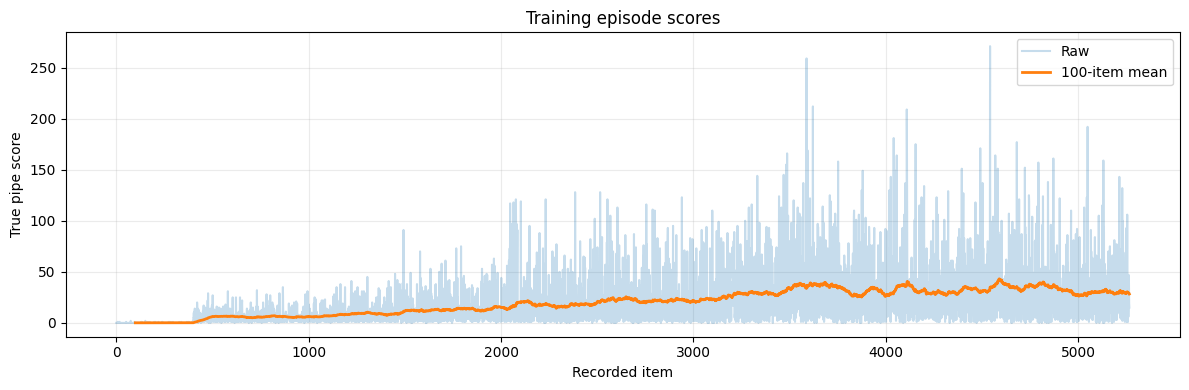

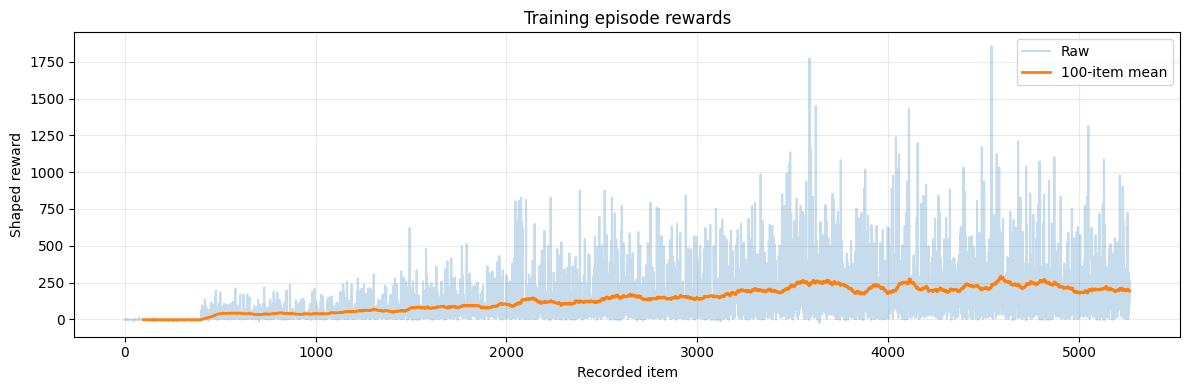

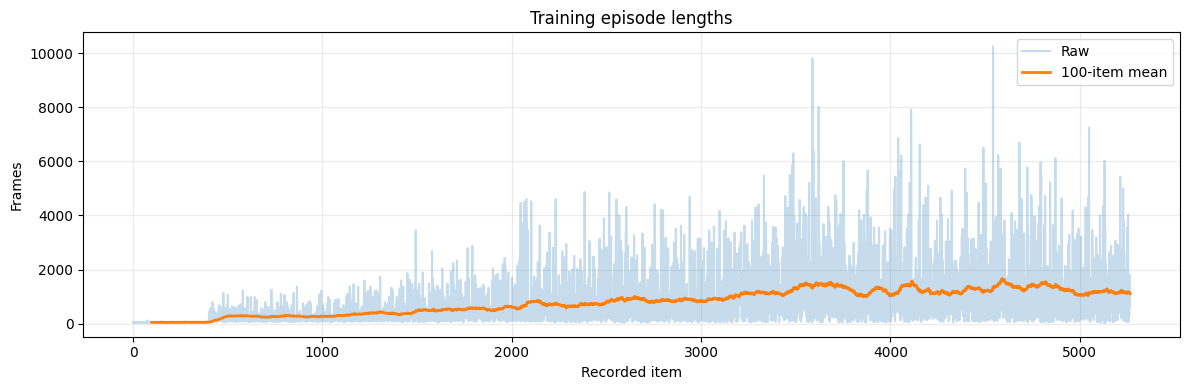

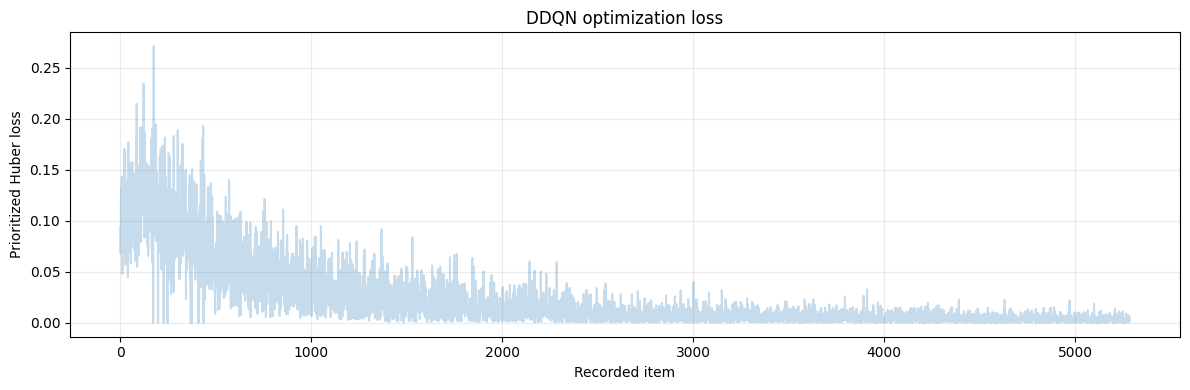

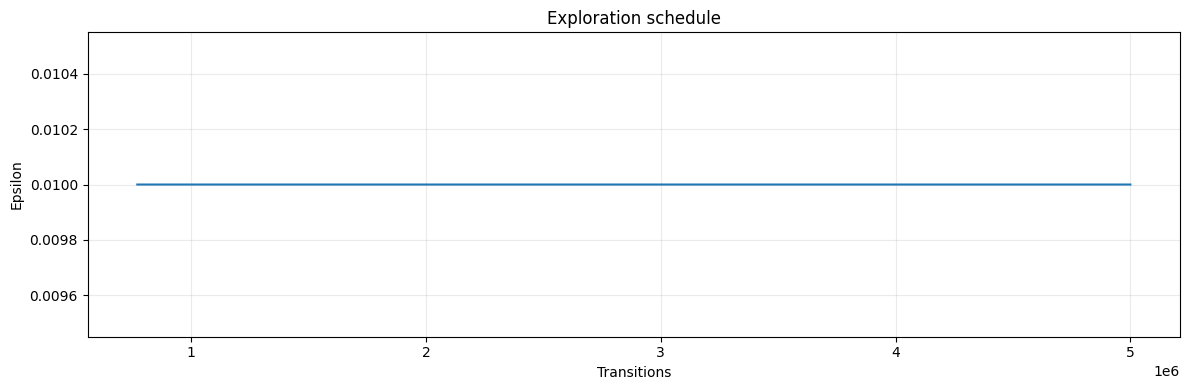

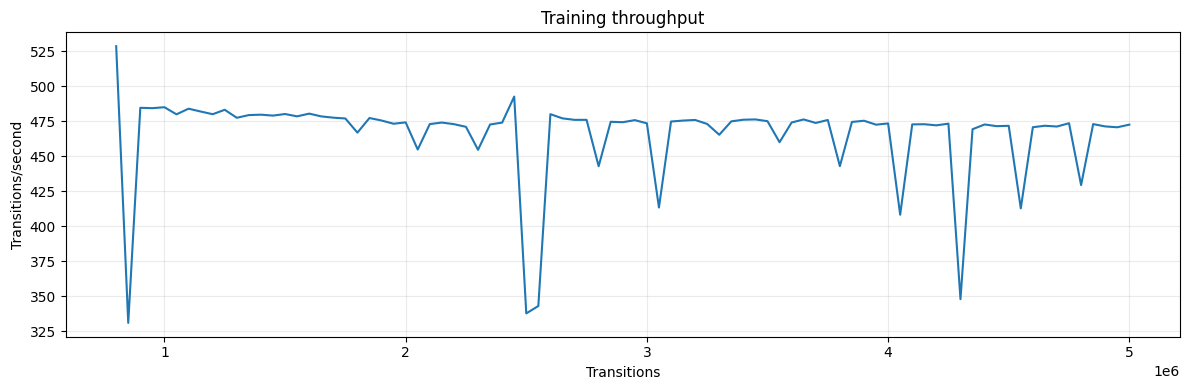

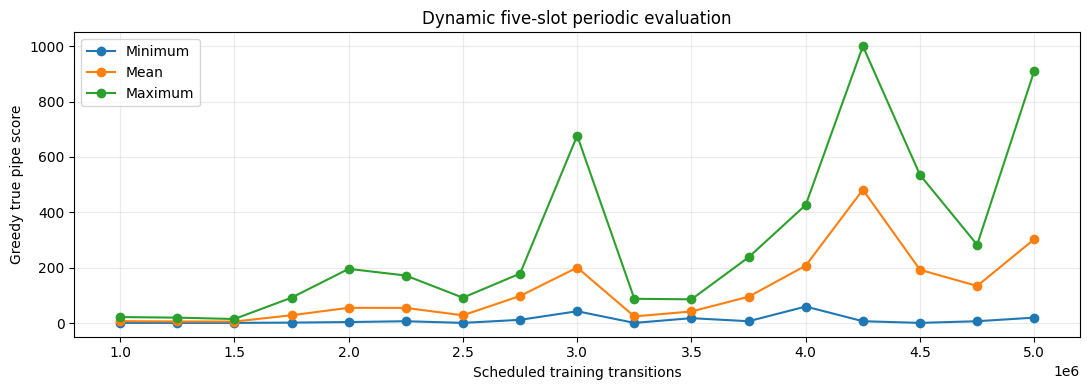

In [11]:
def moving_average(values, window=100):
    values = np.asarray(values, dtype=np.float32)
    if values.size == 0:
        return np.asarray([]), np.asarray([])
    window = min(int(window), len(values))
    kernel = np.ones(window, dtype=np.float32) / window
    return np.arange(window - 1, len(values)), np.convolve(values, kernel, mode="valid")


def save_line_plot(path, values, ylabel, title, smoothed=True):
    values = np.asarray(values, dtype=np.float32)
    figure, axis = plt.subplots(figsize=(12, 4))
    if values.size:
        axis.plot(values, alpha=0.25, label="Raw")
        if smoothed:
            x_values, mean = moving_average(values)
            axis.plot(x_values, mean, linewidth=2, label="100-item mean")
            axis.legend()
    else:
        axis.text(0.5, 0.5, "No data recorded", ha="center", va="center")
    axis.set_xlabel("Recorded item")
    axis.set_ylabel(ylabel)
    axis.set_title(title)
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    plt.show()
    plt.close(figure)


def save_xy_plot(path, x_values, y_values, xlabel, ylabel, title):
    figure, axis = plt.subplots(figsize=(12, 4))
    if len(x_values):
        axis.plot(x_values, y_values, linewidth=1.5)
    else:
        axis.text(0.5, 0.5, "No data recorded", ha="center", va="center")
    axis.set_xlabel(xlabel)
    axis.set_ylabel(ylabel)
    axis.set_title(title)
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    plt.show()
    plt.close(figure)


if TRAINING_RESULT and TRAINING_RESULT["training_completed"]:
    history = TRAINING_RESULT["history"]
    save_line_plot(RUN_DIR / "training_scores.png", history["episode_scores"], "True pipe score", "Training episode scores")
    save_line_plot(RUN_DIR / "episode_rewards.png", history["episode_rewards"], "Shaped reward", "Training episode rewards")
    save_line_plot(RUN_DIR / "episode_lengths.png", history["episode_lengths"], "Frames", "Training episode lengths")
    save_line_plot(RUN_DIR / "training_loss.png", history["losses"], "Prioritized Huber loss", "DDQN optimization loss", smoothed=False)
    save_xy_plot(RUN_DIR / "epsilon_schedule.png", history["epsilon_steps"], history["epsilon_values"], "Transitions", "Epsilon", "Exploration schedule")
    save_xy_plot(RUN_DIR / "throughput.png", history["throughput_steps"], history["throughput_tps"], "Transitions", "Transitions/second", "Training throughput")

    evaluations = TRAINING_RESULT["evaluation_history"]
    figure, axis = plt.subplots(figsize=(11, 4))
    if evaluations:
        steps = [item["scheduled_training_step"] for item in evaluations]
        for label, key in (("Minimum", "minimum_score"), ("Mean", "mean_score"), ("Maximum", "maximum_score")):
            axis.plot(steps, [item[key] for item in evaluations], marker="o", label=label)
        axis.legend()
    else:
        axis.text(0.5, 0.5, "No periodic evaluations in this run", ha="center")
    axis.set_xlabel("Scheduled training transitions")
    axis.set_ylabel("Greedy true pipe score")
    axis.set_title("Dynamic five-slot periodic evaluation")
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(RUN_DIR / "evaluation_scores.png", dpi=150)
    plt.show()
    plt.close(figure)
else:
    print("Skipping plots: no completed training result in this run.")


## 12. Demonstration GIF

Model decisions still occur every environment frame; only captured display
frames are thinned. The overlay includes model name, score, and seed, with
one modest resize/compression pass used only if the GIF exceeds the
transfer-friendly size target.


In [12]:
GIF_PATH = None
GIF_TARGET_SCORE = 100
GIF_MAX_STEPS = 10_000
GIF_CAPTURE_EVERY = 4
GIF_DISPLAY_FPS = 8
GIF_MAX_SIZE_MB = 20.0


def annotate_gif_frame(frame, model_name, score, seed):
    image = PILImage.fromarray(frame)
    draw = ImageDraw.Draw(image)
    draw.rectangle((6, 6, 210, 66), fill=(0, 0, 0))
    draw.text((12, 10), model_name, fill=(255, 255, 255))
    draw.text((12, 29), f"Score: {score}", fill=(255, 255, 255))
    draw.text((12, 48), f"Seed: {seed}", fill=(255, 255, 255))
    return np.asarray(image)


if EXPORTED_MODEL_PATH is not None:
    gif_model, _ = load_model_from_checkpoint(EXPORTED_MODEL_PATH, device=DEVICE)
    gif_env = make_evaluation_env(GIF_TARGET_SCORE, render_mode="rgb_array")
    frames = []
    score = 0
    try:
        observation, info = gif_env.reset(seed=GIF_SEED)
        score = int(info.get("score", 0))
        frames.append(annotate_gif_frame(gif_env.render(), "Dueling DDQN v2", score, GIF_SEED))
        for gif_step in range(1, GIF_MAX_STEPS + 1):
            action = int(gif_model.choose_actions(np.expand_dims(observation, axis=0), epsilon=0.0)[0])
            observation, _, terminated, truncated, info = gif_env.step(action)
            score = int(info.get("score", score))
            if gif_step % GIF_CAPTURE_EVERY == 0 or terminated or truncated:
                frames.append(annotate_gif_frame(gif_env.render(), "Dueling DDQN v2", score, GIF_SEED))
            if terminated or truncated:
                break
    finally:
        gif_env.close()

    GIF_PATH = RUN_DIR / "demonstration.gif"
    imageio.mimsave(GIF_PATH, frames, fps=GIF_DISPLAY_FPS, loop=0)
    gif_size_mb = GIF_PATH.stat().st_size / (1024 ** 2)
    if gif_size_mb > GIF_MAX_SIZE_MB:
        compressed = []
        for frame in frames[::2]:
            image = PILImage.fromarray(frame)
            image = image.resize(
                (max(1, int(image.width * 0.75)), max(1, int(image.height * 0.75))),
                PILImage.Resampling.LANCZOS,
            )
            compressed.append(np.asarray(image))
        imageio.mimsave(GIF_PATH, compressed, fps=max(5, GIF_DISPLAY_FPS // 2), loop=0)
        frames = compressed
        gif_size_mb = GIF_PATH.stat().st_size / (1024 ** 2)

    dimensions = PILImage.fromarray(frames[0]).size
    print(f"GIF achieved score: {score}")
    print(f"GIF seed: {GIF_SEED}")
    print(f"GIF frames: {len(frames)}")
    print(f"GIF dimensions: {dimensions[0]}x{dimensions[1]}")
    print(f"GIF size: {gif_size_mb:.2f} MB")
    print(f"GIF path: {GIF_PATH}")
else:
    print("Skipping demonstration GIF: no exported model in this run.")


GIF achieved score: 100
GIF seed: 900001
GIF frames: 949
GIF dimensions: 288x512
GIF size: 14.88 MB
GIF path: <repo>\artifacts\ddqn_local_v2\demonstration.gif


## 13. Compact result summary

This notebook ends here after training, evaluation, saving, and reporting.
Use `play_improved_model.py` (see the repository root) for interactive or
live inference against the exported checkpoint.


In [13]:
RESULT_SUMMARY = None
if TRAINING_RESULT and TRAINING_RESULT["training_completed"]:
    RESULT_SUMMARY = {
        "experiment_name": EXPERIMENT_NAME,
        "configured_budget": TOTAL_TRANSITIONS,
        "actual_training_transitions": TRAINING_RESULT["global_step"],
        "training_duration_seconds": TRAINING_RESULT["training_seconds"],
        "worker_configuration": {
            "n_envs": N_ENVS, "torch_threads": TORCH_THREADS, "gradient_steps": GRADIENT_STEPS,
            "approx_transitions_per_update": APPROX_TRANSITIONS_PER_UPDATE,
        },
        "best_checkpoint_step": TRAINING_RESULT["best_checkpoint_step"],
        "best_periodic_ranking_key": list(TRAINING_RESULT["best_ranking_key"]),
        "final_periodic_active_seeds": TRAINING_RESULT["evaluation_state"]["active_eval_seeds"],
        "final_periodic_score_limit": TRAINING_RESULT["evaluation_state"]["evaluation_score_limit"],
        "final_unseen_holdout_seeds": FINAL_HOLDOUT_SEEDS,
        "final_unseen_holdout_scores": FINAL_EVALUATION["scores"] if FINAL_EVALUATION else None,
        "final_unseen_holdout_statistics": (
            {
                "mean": FINAL_EVALUATION["mean_score"],
                "median": FINAL_EVALUATION["median_score"],
                "std": FINAL_EVALUATION["std_score"],
                "minimum": FINAL_EVALUATION["minimum_score"],
                "maximum": FINAL_EVALUATION["maximum_score"],
            }
            if FINAL_EVALUATION else None
        ),
        "exported_model_path": str(EXPORTED_MODEL_PATH) if EXPORTED_MODEL_PATH else None,
        "gif_path": str(GIF_PATH) if GIF_PATH else None,
    }
    write_json(RUN_DIR / "result_summary.json", RESULT_SUMMARY)

    if RUN_MODE == "full":
        latest_pointer = ARTIFACTS_ROOT / "latest_run.txt"
        temporary_pointer = latest_pointer.with_suffix(".txt.tmp")
        temporary_pointer.write_text(RUN_DIR.relative_to(PROJECT_ROOT).as_posix() + "\n", encoding="utf-8")
        os.replace(temporary_pointer, latest_pointer)

    print(json.dumps(RESULT_SUMMARY, indent=2))
    if RUN_MODE == "smoke":
        print("SMOKE RUN ONLY: these results validate execution and must not be reported as successful full-budget training.")
elif RUN_MODE == "benchmark":
    print("Benchmark-only execution complete; no training model was produced.")
elif TRAINING_RESULT and TRAINING_RESULT["interrupted"]:
    print(f"Training interrupted at {TRAINING_RESULT['global_step']:,} transitions. Re-run this notebook to resume automatically.")
else:
    print("Training did not complete.")


{
  "experiment_name": "ddqn_local_v2",
  "configured_budget": 5000000,
  "actual_training_transitions": 5000000,
  "training_duration_seconds": 9206.338402599999,
  "worker_configuration": {
    "n_envs": 8,
    "torch_threads": 2,
    "gradient_steps": 1,
    "approx_transitions_per_update": 8.0
  },
  "best_checkpoint_step": 4250000,
  "best_periodic_ranking_key": [
    1000,
    2,
    7,
    481.6,
    1000
  ],
  "final_periodic_active_seeds": [
    1,
    2,
    3,
    6,
    7
  ],
  "final_periodic_score_limit": 2000,
  "final_unseen_holdout_seeds": [
    1000001,
    1000002,
    1000003,
    1000004,
    1000005
  ],
  "final_unseen_holdout_scores": [
    1187,
    301,
    235,
    190,
    85
  ],
  "final_unseen_holdout_statistics": {
    "mean": 399.6,
    "median": 235.0,
    "std": 399.9297938388687,
    "minimum": 85,
    "maximum": 1187
  },
  "exported_model_path": "<repo>\\artifacts\\ddqn_local_v2\\exported_model.pt",
  "gif_path": "<repo>\\artifacts\\ddqn_local_v2